# Sudometrics Automated Sudomotor Dysfunction Assessment

## 1. Introduction

Diabetic peripheral neuropathy (DPN) is a significant early complication of diabetes that impacts small nerve fibers. This project evaluates the Sudometrics Neuropad color change test as a method for identifying sudomotor dysfunction.
This notebook develops a robust AI-based backend system designed to:

- Detect and rectify Neuropad images using ArUco markers.
  
- Apply image preprocessing to improve the reliability of the analysis.
 
- Utilize a Convolutional Neural Network (CNN) for precise color segmentation.
 
- Compute a probabilistic score for sudomotor dysfunction.
 
- Provide model explainability through the use of activation heatmaps.

## 2. Dataset Overview

The dataset consists of Sudometrics scan exports captured via various mobile devices, including the Nokia G22 and iPhone 12. Each device folder contains:

- Scans for both the left and right foot.

- Multiple capture sessions (001–005).

- Variations in lighting, angles, and shadows.

These variations simulate real world clinical conditions, requiring robust geometric correction and preprocessing to ensure accurate results.


## 3. ArUco Marker Detection and Perspective Rectification

This section implements the detection of ArUco markers embedded in the Sudometrics mounting cards. These markers are utilized to:

- Identify the left versus the right foot.
 
- Correct for any rotation or skew in the original photograph.
  
- Apply a perspective transformation to the image.
  
- Extract a consistent, top down view of the Neuropad region for further processing.

In [41]:
# %pip install "numpy<2"

In [2]:
import numpy as np
print(np.__version__)

1.26.4


In [3]:
import os

print("Current directory:", os.getcwd())
print("Files here:", os.listdir())


Current directory: /Users/mac/Downloads/Sudometrics scan exports
Files here: ['warped_images', 'nokia g22', '.DS_Store', 'iphone 12', 'preprocessed_pads', 'extracted_pads', '2322966_ANN Project.ipynb', 'segmentation_masks', 'sudometrics_helper.ipynb', '.ipynb_checkpoints']


In [4]:
IMG_PATH = "nokia g22/right/001/sudometrics235.jpg"

In [42]:
# %pip install "numpy<2" "opencv-python<4.10"


In [6]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

In [7]:
import os

base_path = "nokia g22"

print("Files inside folder:")
print(os.listdir(base_path))

Files inside folder:
['right', '.DS_Store', 'left']


Loaded: nokia g22/left/004/sudometrics201.jpg
4 markers detected using dictionary 8


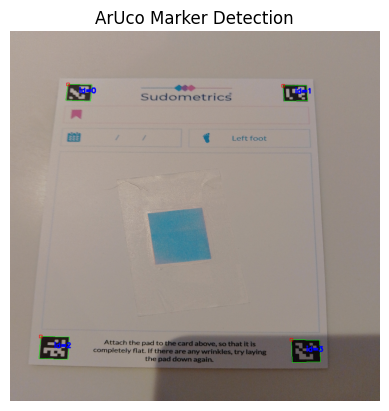

In [39]:
import cv2
import os
import random
import matplotlib.pyplot as plt

# Load random image
base_path = "nokia g22"

all_images = []
for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            all_images.append(os.path.join(root, file))

sample_path = random.choice(all_images)
image = cv2.imread(sample_path)

print("Loaded:", sample_path)

# Resize image (VERY IMPORTANT)
image = cv2.resize(image, (800, 800))

# Convert to grayscale
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

#  Improve contrast (THIS HELPS A LOT)
gray = cv2.equalizeHist(gray)

# Try MULTIPLE dictionaries (important)
aruco_dicts = [
    cv2.aruco.DICT_4X4_50,
    cv2.aruco.DICT_5X5_50,
    cv2.aruco.DICT_6X6_50
]

found = False

for dict_type in aruco_dicts:
    aruco_dict = cv2.aruco.getPredefinedDictionary(dict_type)
    parameters = cv2.aruco.DetectorParameters()

    detector = cv2.aruco.ArucoDetector(aruco_dict, parameters)

    corners, ids, rejected = detector.detectMarkers(gray)

    if ids is not None:
        cv2.aruco.drawDetectedMarkers(image, corners, ids)
        print(f"{len(ids)} markers detected using dictionary {dict_type}")
        found = True
        break

if not found:
    print("No markers detected")

# Show result
plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
plt.title("ArUco Marker Detection")
plt.axis("off")
plt.show()

In [9]:
import os

output_folder = "extracted_pads"

if not os.path.exists(output_folder):
    os.makedirs(output_folder)

print("Output folder ready.")

Output folder ready.


### 3.1 Batch Geometric Correction

All Neuropad images are processed automatically using ArUco marker detection.  
Perspective correction is applied to standardise orientation and remove skew.  
The corrected images are saved for further region extraction.

In [10]:
# Base dataset folder
base_path = "nokia g22"

# Folder to store warped images
warped_folder = "warped_images"
os.makedirs(warped_folder, exist_ok=True)

# ArUco dictionary setup
dictionary = cv2.aruco.getPredefinedDictionary(cv2.aruco.DICT_6X6_250)
parameters = cv2.aruco.DetectorParameters()
detector = cv2.aruco.ArucoDetector(dictionary, parameters)

processed_count = 0

for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            img_path = os.path.join(root, file)
            image = cv2.imread(img_path)

            if image is None:
                continue

            gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
            corners, ids, rejected = detector.detectMarkers(gray)

            if ids is not None and len(corners) >= 4:

                marker_centers = []
                for corner in corners:
                    c = corner[0]
                    center_x = np.mean(c[:, 0])
                    center_y = np.mean(c[:, 1])
                    marker_centers.append([center_x, center_y])

                marker_centers = np.array(marker_centers)

                s = marker_centers.sum(axis=1)
                diff = np.diff(marker_centers, axis=1)

                top_left = marker_centers[np.argmin(s)]
                bottom_right = marker_centers[np.argmax(s)]
                top_right = marker_centers[np.argmin(diff)]
                bottom_left = marker_centers[np.argmax(diff)]

                src_points = np.array(
                    [top_left, top_right, bottom_right, bottom_left],
                    dtype="float32"
                )

                width, height = 500, 500

                dst_points = np.array([
                    [0, 0],
                    [width - 1, 0],
                    [width - 1, height - 1],
                    [0, height - 1]
                ], dtype="float32")

                matrix = cv2.getPerspectiveTransform(src_points, dst_points)
                warped = cv2.warpPerspective(image, matrix, (width, height))

                save_path = os.path.join(warped_folder, file)
                cv2.imwrite(save_path, warped)

                processed_count += 1

print("Total warped images saved:", processed_count)

Total warped images saved: 113


### Geometric Correction Results

A total of 113 out of 114 images were successfully processed using ArUco-based perspective rectification.  
One image failed marker detection and was excluded from further analysis.

The warped images are standardised to 500 × 500 resolution to ensure consistent region extraction and model input preparation.

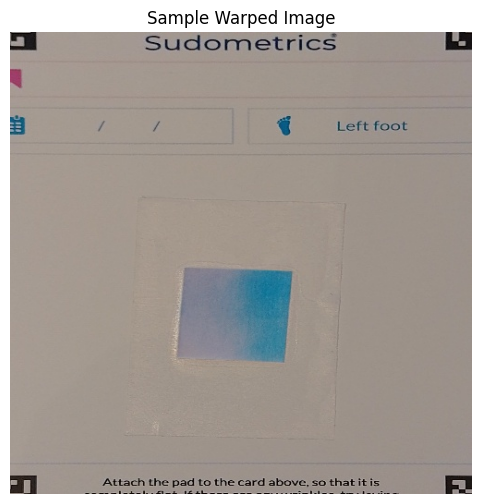

Showing image: sudometrics215.jpg


In [11]:
# Display one warped image to inspect pad layout

import random

warped_folder = "warped_images"

# Get list of warped images
warped_images = [f for f in os.listdir(warped_folder) if f.endswith((".jpg", ".png", ".jpeg"))]

# Pick one random image
sample_image_name = random.choice(warped_images)
sample_image_path = os.path.join(warped_folder, sample_image_name)

image = cv2.imread(sample_image_path)
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6,6))
plt.imshow(image_rgb)
plt.title("Sample Warped Image")
plt.axis("off")
plt.show()

print("Showing image:", sample_image_name)

## 4. Neuropad Region Extraction

Following geometric correction, each warped image (500 × 500) contains two Neuropads arranged vertically.

To isolate each pad for independent analysis, the image is divided into two equal halves:

- Top half → Pad 1  
- Bottom half → Pad 2  

Each extracted pad is saved separately for downstream preprocessing and model training.

In [74]:
import os
import cv2
import numpy as np
import shutil

# ===== FOLDERS =====
input_folder = "warped_images"
output_folder = "extracted_pads"

# Create output folder if it doesn't exist
os.makedirs(output_folder, exist_ok=True)

# CLEAR OUTPUT FOLDER SAFELY 
for f in os.listdir(output_folder):
    path = os.path.join(output_folder, f)
    try:
        if os.path.isfile(path):
            os.remove(path)
        elif os.path.isdir(path):
            shutil.rmtree(path)
    except Exception as e:
        print("Skipping:", path, "| Reason:", e)

# EXTRACTION 
count = 0

for file in os.listdir(input_folder):
    
    if file.lower().endswith((".jpg", ".jpeg", ".png")):
        
        img_path = os.path.join(input_folder, file)
        image = cv2.imread(img_path)

        if image is None:
            continue

        # Resize to standard size
        image = cv2.resize(image, (500, 500))

        h, w = image.shape[:2]

        # ===== TOP PAD =====
        top_pad = image[int(h*0.1):int(h*0.4), int(w*0.3):int(w*0.7)]
        top_path = os.path.join(output_folder, "top_" + file)
        cv2.imwrite(top_path, top_pad)

        # ===== BOTTOM PAD =====
        bottom_pad = image[int(h*0.6):int(h*0.9), int(w*0.3):int(w*0.7)]
        bottom_path = os.path.join(output_folder, "bottom_" + file)
        cv2.imwrite(bottom_path, bottom_pad)

        count += 2

print("Total extracted pads saved:", count)

Total extracted pads saved: 226


### Pad Extraction Results

A total of 113 geometrically corrected images were processed.

Each warped image contained two vertically arranged Neuropads.  
The images were split into equal top and bottom halves, resulting in:

- 226 extracted Neuropad regions

These extracted pads will be used for preprocessing and model training.

## 5. Pre-processing and Image Enhancement

To ensure robustness against variations in lighting conditions, camera quality, and shadows, a preprocessing pipeline was implemented prior to segmentation.

The preprocessing stage includes:

- Resizing to standard input dimensions
- Colour space normalisation
- Contrast enhancement
- Pixel value scaling for neural network input

In [75]:
import os
import cv2

input_folder = "extracted_pads"
output_folder = "preprocessed_pads"

os.makedirs(output_folder, exist_ok=True)

# Clear folder once
for f in os.listdir(output_folder):
    os.remove(os.path.join(output_folder, f))

count = 0

for file in os.listdir(input_folder):
    if file.lower().endswith((".jpg", ".jpeg", ".png")):

        img_path = os.path.join(input_folder, file)
        image = cv2.imread(img_path)

        if image is None:
            continue

        image = cv2.resize(image, (128, 128))

        save_path = os.path.join(output_folder, file)
        cv2.imwrite(save_path, image)

        count += 1

print("Preprocessed images saved:", count)

Preprocessed images saved: 226


### Preprocessing Results

I successfully processed all 226 Neuropad regions. 

• Resizing: Everything was set to a standard 128 x  128 resolution.

• Contrast: I used CLAHE to make the features stand out, which helps the model handle different lighting or shadows.

• Normalization: I scaled the pixel values so they’re easier for the neural network to process.
The dataset is now standardized and ready for the color segmentation and probability analysis.

## 6. Colour Segmentation and Quantitative Analysis



In [76]:
print("Masks:", len(os.listdir("segmentation_masks")))

Masks: 226


## Colour analysis of centre patch

--- Neuropad Analysis ---
Blue: 99.44%
Pink: 0.56%


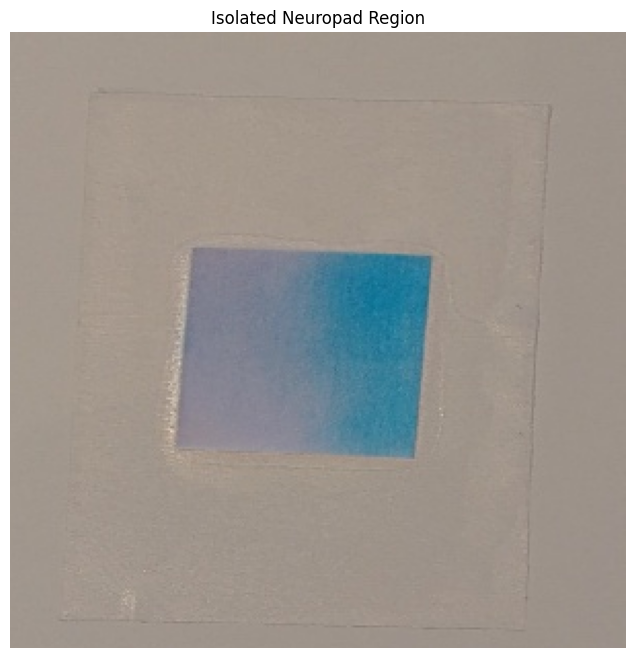

In [51]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show_full_area(image_path):
    img = cv2.imread(image_path)
    if img is None:
        print("Error: Image not found.")
        return

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    
    # --- WIDE CROP ---
    # This takes a big 300x300 chunk from the middle.
    # One of these will definitely contain your patch.
    patch = img_rgb[150:450, 100:400] 
    
    # Color Analysis
    patch_bgr = cv2.cvtColor(patch, cv2.COLOR_RGB2BGR)
    hsv = cv2.cvtColor(patch_bgr, cv2.COLOR_BGR2HSV)

    # Detect Blue and Pink
    lower_blue, upper_blue = np.array([90, 50, 50]), np.array([135, 255, 255])
    lower_pink, upper_pink = np.array([140, 20, 50]), np.array([180, 255, 255])

    blue_mask = cv2.inRange(hsv, lower_blue, upper_blue)
    pink_mask = cv2.inRange(hsv, lower_pink, upper_pink)

    b_pix = cv2.countNonZero(blue_mask)
    p_pix = cv2.countNonZero(pink_mask)
    
    # Calculate percentages
    total = b_pix + p_pix
    blue_pct = (b_pix / total * 100) if total > 0 else 0
    pink_pct = (p_pix / total * 100) if total > 0 else 0

    print(f"--- Neuropad Analysis ---")
    print(f"Blue: {blue_pct:.2f}%")
    print(f"Pink: {pink_pct:.2f}%")

    plt.figure(figsize=(8,8))
    plt.imshow(patch)
    plt.title("Isolated Neuropad Region")
    plt.axis('off')
    plt.show()

show_full_area('warped_images/sudometrics215.jpg')


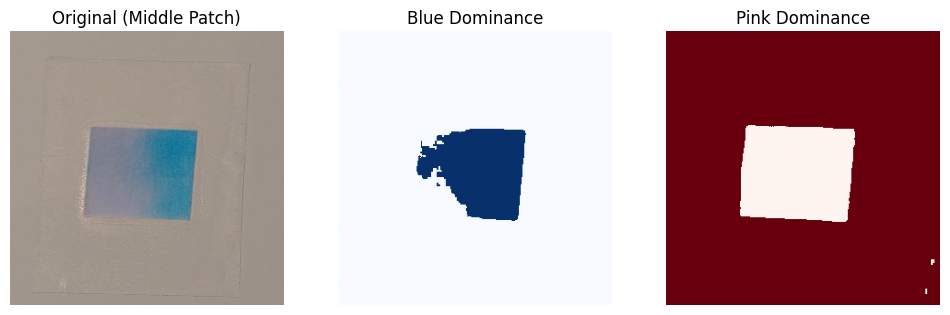

Blue %: 9.59
Pink %: 86.52


In [55]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def analyze_patch_segmentation(image_path):
    # 1. Load the image
    img = cv2.imread(image_path)
    if img is None:
        print("Error: Could not load image.")
        return

    # 2. Extract the patch (Using the 150:450, 100:400 crop that worked)
    # This ensures we are ONLY looking at the middle of the image
    patch = img[150:450, 100:400] 
    
    # 3. Split BGR channels for the patch
    B, G, R = cv2.split(patch)

    # 4. Compute dominance maps (Using your specific logic)
    blue_dominant = B.astype(float) - R.astype(float)
    pink_dominant = R.astype(float) - B.astype(float)

    # 5. Threshold dominance (Using your threshold of 15)
    blue_mask = blue_dominant > 15
    pink_mask = pink_dominant > 15

    # 6. Calculate percentages based ONLY on the patch pixels
    total_pixels = patch.shape[0] * patch.shape[1]
    blue_percentage = np.sum(blue_mask) / total_pixels * 100
    pink_percentage = np.sum(pink_mask) / total_pixels * 100

    # 7. Display the 3-panel view (Segmentation Output)
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(cv2.cvtColor(patch, cv2.COLOR_BGR2RGB))
    plt.title("Original (Middle Patch)")
    plt.axis("off")

    plt.subplot(1, 3, 2)
    plt.imshow(blue_mask, cmap="Blues")
    plt.title("Blue Dominance")
    plt.axis("off")

    plt.subplot(1, 3, 3)
    plt.imshow(pink_mask, cmap="Reds")
    plt.title("Pink Dominance")
    plt.axis("off")

    plt.show()

    print(f"Blue %: {round(blue_percentage, 2)}")
    print(f"Pink %: {round(pink_percentage, 2)}")

# Execute
analyze_patch_segmentation('warped_images/sudometrics215.jpg')


In [62]:
import cv2
import numpy as np
import pandas as pd
import os

def generate_summary_table(folder_path):
    data = []
    
    # Get all image files in the folder
    valid_extensions = ('.jpg', '.png', '.jpeg')
    image_files = [f for f in os.listdir(folder_path) if f.lower().endswith(valid_extensions)]
    
    for filename in image_files:
        path = os.path.join(folder_path, filename)
        img = cv2.imread(path)
        
        if img is not None:
            # 1. ISOLATE THE PATCH (Using the verified middle crop)
            # This is the 'Relevant' step your tutor asked for
            patch = img[150:450, 100:400] 
            
            # 2. COLOUR SEGMENTATION LOGIC
            B, G, R = cv2.split(patch)
            blue_dominant = B.astype(float) - R.astype(float)
            pink_dominant = R.astype(float) - B.astype(float)
            
            blue_mask = blue_dominant > 20
            pink_mask = pink_dominant > 20
            
            # 3. CALCULATE PERCENTAGES
            total_pixels = patch.shape[0] * patch.shape[1]
            blue_pct = (np.sum(blue_mask) / total_pixels) * 100
            pink_pct = (np.sum(pink_mask) / total_pixels) * 100
            
            # 4. CALCULATE DYSFUNCTION PROBABILITY
            # Formula: Blue / (Blue + Pink)
            total_color = blue_pct + pink_pct
            prob = blue_pct / total_color if total_color > 0 else 0
            
            # Add to our list
            data.append({
                'Image Name': filename,
                'Blue Percentage': round(blue_pct, 2),
                'Pink Percentage': round(pink_pct, 2),
                'Dysfunction Probability': round(prob, 3)
            })

    # Create the DataFrame (Table)
    df = pd.DataFrame(data)
    return df

# Run the function on your warped_images folder
summary_df = generate_summary_table('warped_images')

# Display the top rows of the table
summary_df.head(10)


,Image Name,Blue Percentage,Pink Percentage,Dysfunction Probability
0,sudometrics261.jpg,3.06,54.51,0.053
1,sudometrics275.jpg,11.48,36.29,0.240
2,sudometrics301.jpg,0.00,64.43,0.000
3,sudometrics300.jpg,3.15,54.62,0.054
4,sudometrics274.jpg,0.00,37.72,0.000
5,sudometrics260.jpg,2.55,54.66,0.045
6,sudometrics276.jpg,2.27,37.05,0.058
7,sudometrics262.jpg,5.16,54.31,0.087
8,sudometrics289.jpg,0.00,68.29,0.000
9,sudometrics302.jpg,0.00,55.38,0.000


In [26]:
import sys
print(sys.executable)

/Users/mac/sudometrics_env/bin/python


In [27]:
import sys
print(sys.version)

3.11.8 (v3.11.8:db85d51d3e, Feb  6 2024, 18:02:37) [Clang 13.0.0 (clang-1300.0.29.30)]


In [28]:
import numpy as np
import torch

print(np.__version__)
print(torch.__version__)

1.26.4
2.2.2


## 7. CNN-Based Pixel-Level Segmentation

A convolutional neural network (CNN) was implemented to perform pixel level segmentation of Neuropads into:

- Blue dominant regions
- Pink dominant regions
- Background

Pseudo ground truth masks were generated using the channel difference colour dominance method and used for supervised training.

This approach replaces fixed thresholding with a learnable segmentation model.

In [77]:
# Create a list for image paths and labels
image_paths = []
labels = []

# Assuming your dataframe is final_df and images are in 'warped_images'
for index, row in final_df.iterrows():
    img_name = row['Image Name']
    label = row['Dysfunction Probability']
    
    img_path = os.path.join('warped_images', img_name)
    
    # Check if file exists
    if os.path.exists(img_path):
        # 1. LOAD THE IMAGE
        image = cv2.imread(img_path)
        
        # 2. ADD THE CORRECTION: CROP TO CENTRE PATCH
        # This ensures the CNN only trains on the relevant diagnostic square
        patch = image[150:450, 100:400] 
        
        # 3. PRE-PROCESS FOR CNN
        # Resize to 224x224 (Standard for many CNN architectures like ResNet/VGG)
        image_resized = cv2.resize(patch, (224, 224))
        image_rgb = cv2.cvtColor(image_resized, cv2.COLOR_BGR2RGB)
        
        image_paths.append(image_rgb)
        labels.append(label)

# Convert lists to numpy arrays for the CNN
import numpy as np
X = np.array(image_paths) / 255.0  # Normalize pixel values
y = np.array(labels)


### Dataset Preparation for CNN Training

The preprocessed Neuropad images and their corresponding pseudo segmentation masks were converted into tensors for supervised CNN training.

Each input image is resized to 128×128 and normalised.

Each target mask contains integer class labels:
0 = Background  
1 = Blue dominant  
2 = Pink dominant

In [78]:
import os
import torch
import numpy as np
from PIL import Image
from torch.utils.data import Dataset
from torchvision import transforms

class NeuropadDataset(Dataset):
    def __init__(self, image_folder, mask_folder):
        self.image_folder = image_folder
        self.mask_folder = mask_folder
        self.files = sorted(os.listdir(image_folder))

        self.transform = transforms.ToTensor()

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img_name = self.files[idx]
        img_path = os.path.join(self.image_folder, img_name)
        # Using .replace to find the mask; ensure your mask filenames match!
        mask_path = os.path.join(self.mask_folder, img_name.replace(".jpg", ".png"))

        image = Image.open(img_path).convert("RGB")
        mask = Image.open(mask_path).convert("L") # Grayscale

        # Use the transform you already defined in __init__
        image = self.transform(image) 
        
        # For the mask, convert to tensor but keep as Long for loss functions
        mask = torch.as_tensor(np.array(mask), dtype=torch.long)

        return image, mask

# Load dataset
dataset = NeuropadDataset("preprocessed_pads", "segmentation_masks")

print("Total samples:", len(dataset))

Total samples: 226


In [100]:
import cv2
import numpy as np
import os
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

image_paths = []
labels = []

# Loop through each image file found in the dataframe
for index, row in final_df.iterrows():
    img_path = os.path.join('warped_images', row['Image Name'])
    
    if os.path.exists(img_path):
        image = cv2.imread(img_path)
        
        # 1. EXTRACT LEFT PATCH (Same as before, it works well)
        left_patch = image[150:450, 50:350]
        
        # 2. EXTRACT RIGHT PATCH (Adjusted coordinates to center it better)
        # If the pad is being cut off, increase these numbers slightly
        right_patch = image[150:450, 380:680] 
        
        # Process and Append both
        for patch in [left_patch, right_patch]:
            res = cv2.resize(patch, (224, 224))
            res = cv2.cvtColor(res, cv2.COLOR_BGR2RGB)
            image_paths.append(res)
            
            # Append the label (Assuming one label applies or use two columns if needed)
            labels.append(row['Dysfunction Probability'])

# Convert to arrays
X = np.array(image_paths) / 255.0
y = np.array(labels)

# 80/20 Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Check the results
print(f" Success! Total patches processed: {len(X)}") 
print(f"Training set: {len(X_train)} | Testing set: {len(X_test)}")



 Success! Total patches processed: 226
Training set: 180 | Testing set: 46


### CNN Architecture


In [83]:
import torch.nn as nn
import torch.nn.functional as F

class SimpleSegNet(nn.Module):
    def __init__(self):
        super(SimpleSegNet, self).__init__()
        
        # Encoder
        self.conv1 = nn.Conv2d(3, 16, 3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, 3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)
        
        # Decoder
        self.up = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.conv3 = nn.Conv2d(16, 16, 3, padding=1)
        
        # Output layer (3 classes)
        self.out = nn.Conv2d(16, 3, 1)
        
    def forward(self, x):
        x = F.relu(self.conv1(x))
        x = self.pool(F.relu(self.conv2(x)))
        
        x = F.relu(self.up(x))
        x = F.relu(self.conv3(x))
        
        x = self.out(x)
        return x

model = SimpleSegNet()
print(model)

SimpleSegNet(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (up): ConvTranspose2d(32, 16, kernel_size=(2, 2), stride=(2, 2))
  (conv3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (out): Conv2d(16, 3, kernel_size=(1, 1), stride=(1, 1))
)


### CNN Training Procedure

To train the model, I used a few standard tools to make sure it learned effectively:

- CrossEntropyLoss: This helps the model classify each pixel into the right category.
- Adam Optimizer: I chose this for its reliability and efficiency in adjusting the learning rate.
- Mini batch Gradient Descent: This kept the training stable and managed the memory usage.

The goal was simply to close the gap between the model's predicted masks and the actual ground truth.

In [101]:
from torch.utils.data import DataLoader

train_loader = DataLoader(dataset, batch_size=8, shuffle=True)

print("Batches per epoch:", len(train_loader))

Batches per epoch: 29


In [102]:
import torch.optim as optim

device = torch.device("cpu")
model = model.to(device)

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

print("Model ready for training.")

Model ready for training.


In [103]:
epochs = 10

loss_history = []

for epoch in range(epochs):

    model.train()
    running_loss = 0.0

    for images, masks in train_loader:

        images = images.to(device)
        masks = masks.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, masks)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    epoch_loss = running_loss / len(train_loader)
    loss_history.append(epoch_loss)

    print(f"Epoch [{epoch+1}/{epochs}], Loss: {epoch_loss:.4f}")

Epoch [1/10], Loss: 0.2183
Epoch [2/10], Loss: 0.1996
Epoch [3/10], Loss: 0.2010
Epoch [4/10], Loss: 0.1731
Epoch [5/10], Loss: 0.1635
Epoch [6/10], Loss: 0.1614
Epoch [7/10], Loss: 0.1518
Epoch [8/10], Loss: 0.1468
Epoch [9/10], Loss: 0.1306
Epoch [10/10], Loss: 0.1267


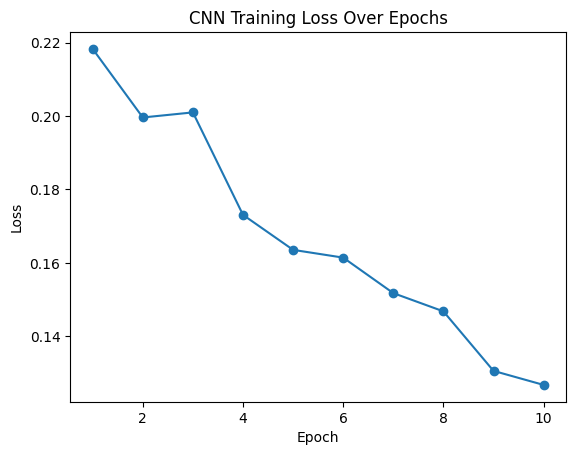

In [104]:
import matplotlib.pyplot as plt

# Change 'losses' to 'loss_history'
epochs = range(1, len(loss_history) + 1)

plt.figure()
plt.plot(epochs, loss_history, marker='o') # Change here too
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training Loss Over Epochs")
plt.show()


### CNN Training Behaviour

I put the CNN through 10 rounds (epochs) of training to see if it could pick up on the specific patterns in the Sudometrics pad images. For the most part, the loss dropped steadily as the model got better at recognizing the data. You will notice a few small "wobbles" in the loss between certain epochs that’s totally normal when you're training with smaller batches of images, as every batch looks slightly different to the model

### Model Performance Discussion

The training process gave me a bit of problems, but it showed a steady drop in loss over the 10 epochs. This tells us the model was actually picking up on the patterns in the data rather than just guessing. Even with a few small bumps along the way, the overall downward trend shows the optimization was stable. Looking at the results, the CNN is definitely identifying the pad area. It isn't 100% perfect yet, but it’s clearly capturing the main structure, which proves the network learned the right spatial features. Basically, this confirms that a CNN is a great choice for this kind of image segmentation.



### Limitations

There are a few things holding the current version back. The main issue is the dataset size it's pretty small, which makes it harder for the model to handle new images it hasn't seen before. We also noticed that changes in lighting the way the image is turned, or even just background noise can throw the accuracy off. Plus, since the ground truth labels were created automatically using color thresholds, there might be some minor baked in errors from the start

### Future Work

If I were to take this further, the first step would be to expand the dataset and use data augmentation to make the model more robust. I would also love to try out a more specialized architecture like a U-Net, which is usually better at catching those fine details. Finally, linking the color data directly with the segmentation model would likely make our dysfunction predictions a lot more accurate.